# 02 · Descriptive Statistics
Module 2.1 (Statistics for Data Science)

Descriptive statistics **summarise** data with a few numbers: where the centre is (mean, median, mode),
how spread out it is (range, IQR, quartile deviation) and what shape it has (skewness, kurtosis).
All formulas are written by hand in `src/stats.py` and then cross-checked against pandas/scipy.

### Setup
We import the usual libraries plus our own `src/` package. `src` holds all reusable code (statistics formulas, outlier detectors, model pipelines, plot styles) so the notebooks and the Streamlit app use exactly the same logic. The random seed is fixed to **42** so every run gives the same numbers.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use our own src/ package
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src import config as C
from src import data, plots
plots.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
np.random.seed(C.RANDOM_STATE)
from src import stats as S

## 1. Load the data
We use the cleaned data where impossible zeros (Cholesterol = 0, RestingBP = 0) are `NaN`.
If we kept those zeros, 172 fake "0 mg/dl" values would pull the cholesterol mean down and distort every statistic.
Missing values are simply skipped in each calculation.

In [2]:
df = data.load_clean()
df[C.CONTINUOUS].head()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,40,140.000,289.000,172,0.000
1,49,160.000,180.000,156,1.000
2,37,130.000,283.000,98,0.000
3,48,138.000,214.000,108,1.500
4,54,150.000,195.000,122,0.000


## 2. The formulas (implemented in `src/stats.py`)
Let $x_1, \dots, x_n$ be the values of one feature, sorted from smallest to largest.

**Measures of central tendency**
* Arithmetic mean: $\bar{x} = \dfrac{\sum x_i}{n}$
* Median: the middle value of the sorted data (average of the two middle values if $n$ is even)
* Mode: the most frequent value
* Weighted mean: $\bar{x}_w = \dfrac{\sum w_i x_i}{\sum w_i}$

**Measures of dispersion**
* Range = max − min
* Quartiles $Q_1$ (25th percentile) and $Q_3$ (75th percentile), using linear interpolation at position $h=(n-1)p$
* Inter-quartile range: IQR = $Q_3 - Q_1$
* Quartile deviation: QD = $\dfrac{Q_3 - Q_1}{2}$
* Sample standard deviation: $s = \sqrt{\dfrac{\sum (x_i-\bar{x})^2}{n-1}}$

**Measures of shape**
* Karl Pearson's coefficient of skewness: $Sk_P = \dfrac{3(\bar{x} - \text{median})}{s}$
* Bowley's coefficient of skewness: $Sk_B = \dfrac{Q_3 + Q_1 - 2\,\text{median}}{Q_3 - Q_1}$ (ranges from −1 to +1)
* Excess kurtosis: $K = \dfrac{m_4}{m_2^2} - 3$ where $m_k = \dfrac{1}{n}\sum (x_i - \bar{x})^k$.
  A normal curve has $K = 0$; $K > 0$ = **leptokurtic** (sharper peak, heavier tails);
  $K < 0$ = **platykurtic** (flatter); $K \approx 0$ = **mesokurtic**. We use ±0.5 as the "close to 0" band.

## 3. Choosing a weighting for the weighted mean
The dataset has **more heart-disease patients (55%) than healthy patients (45%)**. A plain mean therefore leans towards the
heart-disease group. We give each patient a weight of $w_i = \dfrac{1}{\text{size of their class}}$.
Then both classes have the same total weight, and the weighted mean equals the average of the two group means -
a **class-balanced mean**, i.e. the mean we would expect if the two groups were equally common.

In [3]:
weights = S.class_balanced_weights(df[C.TARGET])
print("Weight of one heart-disease patient   :", round(weights[df[C.TARGET].to_numpy() == 1][0], 5))
print("Weight of one no-heart-disease patient:", round(weights[df[C.TARGET].to_numpy() == 0][0], 5))
print("Total weight per class:", pd.Series(weights).groupby(df[C.TARGET].to_numpy()).sum().round(3).to_dict())

Weight of one heart-disease patient   : 0.00197
Weight of one no-heart-disease patient: 0.00244
Total weight per class: {0: 1.0, 1: 1.0}


## 4. Summary table
One row per continuous feature with every measure. (The `N` column shows how many non-missing values were used.)

In [4]:
summary = S.descriptive_table(df, C.CONTINUOUS, weights)
summary.to_csv(C.PROCESSED_DIR / "descriptive_statistics.csv")
summary.round(3)

,N,Mean,Median,Mode,Weighted mean,Std,Min,Max,Range,Q1,Q3,IQR,Quartile dev.,Pearson skew,Bowley skew,Excess kurtosis,Kurtosis type
Feature,,,,,,,,,,,,,,,,,
Age,918,53.511,54.000,54.000,53.225,9.433,28.000,77.000,49.000,47.000,60.000,13.000,6.500,-0.156,-0.077,-0.391,Mesokurtic
RestingBP,917,132.541,130.000,120.000,132.313,18.000,80.000,200.000,120.000,120.000,140.000,20.000,10.000,0.423,0.000,0.781,Leptokurtic
Cholesterol,746,244.635,237.000,254.000,243.984,59.154,85.000,603.000,518.000,207.250,275.000,67.750,33.875,0.387,0.122,4.490,Leptokurtic
MaxHR,918,136.809,138.000,150.000,137.903,25.460,60.000,202.000,142.000,120.000,156.000,36.000,18.000,-0.140,0.000,-0.452,Mesokurtic
Oldpeak,918,0.887,0.600,0.000,0.841,1.067,-2.600,6.200,8.800,0.000,1.500,1.500,0.750,0.808,0.200,1.190,Leptokurtic


## 5. Cross-check against pandas / scipy
To prove the hand-written formulas are correct we compare them with library functions.
(Pandas does not have Pearson/Bowley skewness, so for shape we compare the **moment** skewness and the excess kurtosis
with `scipy.stats.skew` and `scipy.stats.kurtosis(bias=True)`.) The absolute differences should be essentially zero.

In [5]:
check = S.cross_check(df, C.CONTINUOUS)
print("Largest absolute difference across all checks:", f"{check['Abs diff'].max():.2e}")
assert check["Abs diff"].max() < 1e-9, "manual formula does not match the library!"
check.pivot(index="Measure", columns="Feature", values="Abs diff").map(lambda v: f"{v:.1e}")

Largest absolute difference across all checks: 3.55e-14


Feature,Age,Cholesterol,MaxHR,Oldpeak,RestingBP
Measure,,,,,
Excess kurtosis,5.3e-15,1.1e-14,4.4e-16,3.6e-14,2.7e-15
IQR,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00
Mean,0.0e+00,0.0e+00,0.0e+00,2.2e-16,0.0e+00
Median,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00
Mode,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00
Moment skewness,6.4e-16,6.7e-16,9.4e-16,7.8e-15,1.8e-15
Q1,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00
Q3,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00
Std (ddof=1),3.6e-15,0.0e+00,7.1e-15,2.4e-15,7.1e-15


Note: `pandas.Series.kurt()` gives a slightly different number because it uses an *unbiased sample* correction.
Our formula is the population (moment) version that matches `scipy.stats.kurtosis(bias=True)`:

In [6]:
pd.DataFrame({"Our excess kurtosis": summary["Excess kurtosis"],
              "pandas .kurt() (bias-corrected)": df[C.CONTINUOUS].kurt()}).round(3)

,Our excess kurtosis,pandas .kurt() (bias-corrected)
Age,-0.391,-0.386
RestingBP,0.781,0.792
Cholesterol,4.490,4.529
MaxHR,-0.452,-0.448
Oldpeak,1.190,1.203


## 6. Effect of the hidden zeros on Cholesterol
To show why cleaning matters, compare the Cholesterol statistics with and without treating 0 as missing.

In [7]:
raw = data.load_raw()
compare = pd.concat([
    S.descriptive_table(raw, ["Cholesterol"]).assign(Version="Raw (zeros kept)"),
    S.descriptive_table(df, ["Cholesterol"]).assign(Version="Clean (zeros = missing)"),
]).set_index("Version")[["N", "Mean", "Median", "Mode", "Std", "Pearson skew", "Bowley skew", "Excess kurtosis"]]
compare.round(3)

,N,Mean,Median,Mode,Std,Pearson skew,Bowley skew,Excess kurtosis
Version,,,,,,,,
Raw (zeros kept),918,198.800,223.000,0.000,109.384,-0.664,-0.061,0.111
Clean (zeros = missing),746,244.635,237.000,254.000,59.154,0.387,0.122,4.490


## 7. Interpreting skewness in words
* **Positive skew** (right tail): a few large values pull the mean **above** the median.
* **Negative skew** (left tail): a few small values pull the mean **below** the median.
* Pearson's coefficient uses the mean (sensitive to extreme values); Bowley's uses only quartiles (robust to extremes),
  so the two can disagree when a feature has outliers.

In [8]:
for feat, row in summary.iterrows():
    print(f"{feat:12s} Pearson = {row['Pearson skew']:+.3f} -> {S.skew_label(row['Pearson skew']):34s}"
          f" | Bowley = {row['Bowley skew']:+.3f} -> {S.skew_label(row['Bowley skew'])}")

Age          Pearson = -0.156 -> slightly negatively (left) skewed  | Bowley = -0.077 -> approximately symmetric
RestingBP    Pearson = +0.423 -> slightly positively (right) skewed | Bowley = +0.000 -> approximately symmetric
Cholesterol  Pearson = +0.387 -> slightly positively (right) skewed | Bowley = +0.122 -> slightly positively (right) skewed
MaxHR        Pearson = -0.140 -> slightly negatively (left) skewed  | Bowley = +0.000 -> approximately symmetric
Oldpeak      Pearson = +0.808 -> strongly positively (right) skewed | Bowley = +0.200 -> slightly positively (right) skewed


And the kurtosis of each feature:

In [9]:
for feat, row in summary.iterrows():
    print(f"{feat:12s} excess kurtosis = {row['Excess kurtosis']:+.3f} -> {S.kurtosis_type(row['Excess kurtosis'])}")

Age          excess kurtosis = -0.391 -> Mesokurtic (close to normal)
RestingBP    excess kurtosis = +0.781 -> Leptokurtic (peaked, heavy tails)
Cholesterol  excess kurtosis = +4.490 -> Leptokurtic (peaked, heavy tails)
MaxHR        excess kurtosis = -0.452 -> Mesokurtic (close to normal)
Oldpeak      excess kurtosis = +1.190 -> Leptokurtic (peaked, heavy tails)


## 8. Histograms with KDE
A **histogram** shows how many patients fall into each value range; the **KDE** (kernel density estimate) is a smooth
version of it. We draw the two classes separately so we can also see which features differ between them.

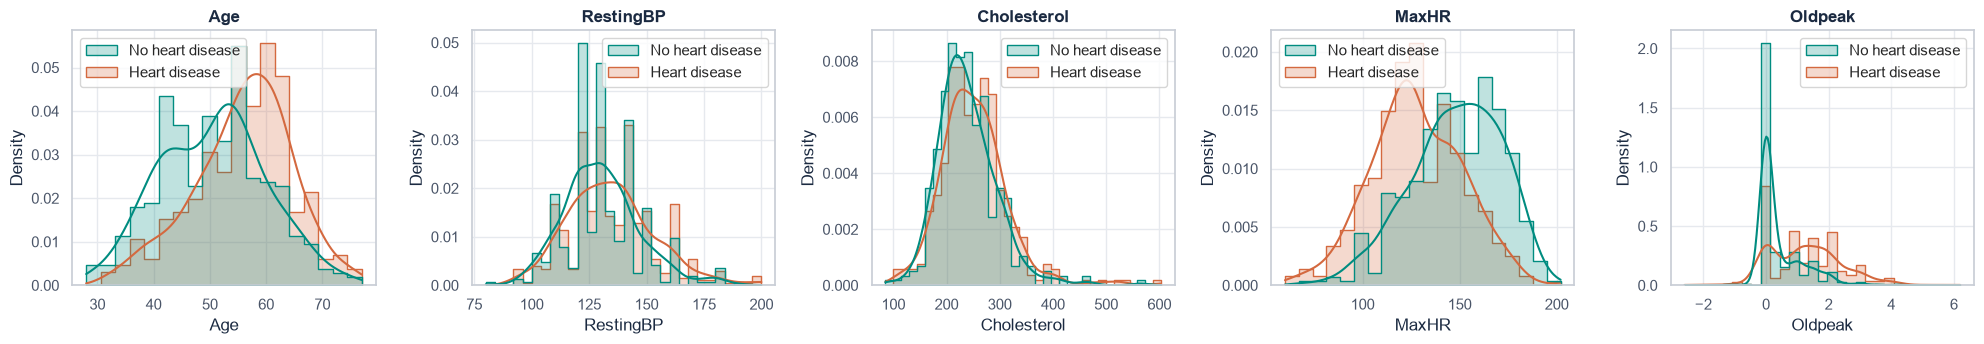

In [10]:
fig = plots.hist_kde_grid(df, C.CONTINUOUS)
plots.save_fig(fig, "02_histograms_kde")
plt.show()

## 9. Box plots
A **box plot** draws Q1, the median and Q3 as a box; the whiskers reach 1.5 × IQR and dots beyond them are possible outliers.

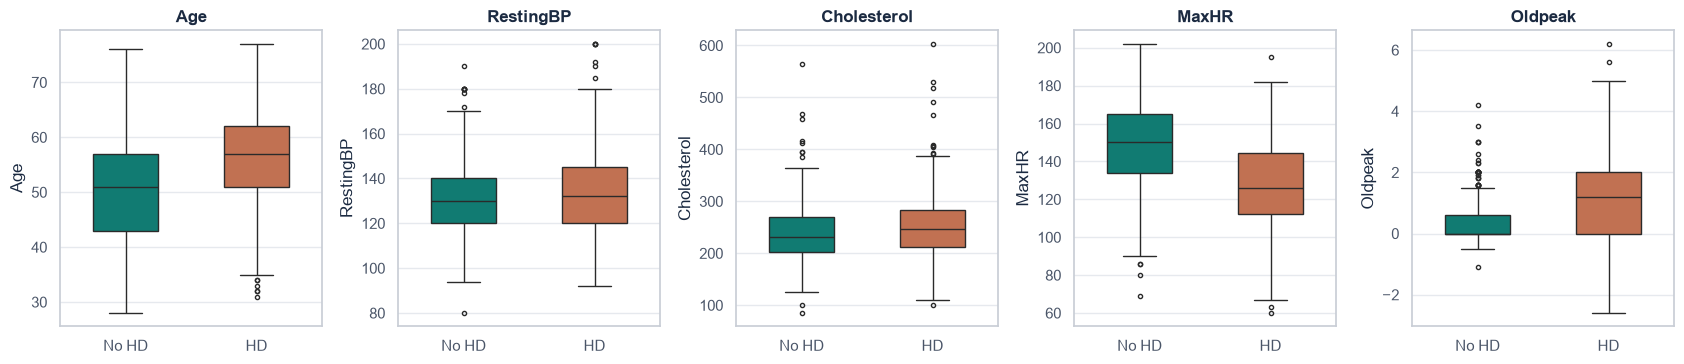

In [11]:
fig = plots.box_grid(df, C.CONTINUOUS)
plots.save_fig(fig, "02_boxplots")
plt.show()

## Key Findings
* **Age** (mean 53.5, median 54) is close to symmetric (Pearson −0.16, Bowley −0.08) and **mesokurtic** - a nicely bell-shaped feature.
* **MaxHR** (mean 136.8, median 138) is slightly left-skewed (Pearson −0.14) and mesokurtic. Heart-disease patients reach a clearly lower maximum heart rate.
* **RestingBP** (mean 132.5, median 130) is slightly right-skewed by Pearson (+0.42) but Bowley = 0 (Q1 and Q3 are symmetric around the median), so the skew comes from a few very high readings in the tail; it is **leptokurtic**.
* **Cholesterol** (after removing zeros: mean 244.6, median 237) is right-skewed and strongly **leptokurtic** (kurtosis 4.5) because of a few extreme values up to 603 mg/dl. Keeping the 172 zeros would have produced a fake mean of about 199 and a strong left skew.
* **Oldpeak** is the most skewed feature (Pearson +0.81): most patients have 0–1.5 mm, a few have up to 6.2 mm; it is leptokurtic.
* The class-balanced weighted means are close to the plain means; the biggest shift is for MaxHR (136.8 → 137.9) because the healthy group has a much higher MaxHR.
* All hand-written formulas match pandas/scipy to within about 1e-13.